# IS 4487 Assignment 7: Data Transformation with Airbnb Listings

In this assignment, you will:
- Load the Airbnb dataset you cleaned in Assignment 6
- Apply data transformation techniques like scaling, binning, encoding, and feature creation
- Make the dataset easier to use for tasks like pricing analysis, guest segmentation, or listing recommendations
- Practice writing up your analysis clearly so a business audience — like a host, marketing manager, or city partner — could understand it

## Why This Matters

Airbnb analysts, hosts, and city partners rely on clean and well-structured data to make smart decisions. Whether they’re adjusting prices, identifying high-performing listings, or designing better guest experiences, they need data that’s transformed, organized, and ready for use.

This assignment helps you practice that kind of real-world thinking: taking messy real data and getting it ready for action.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_07_data_transformation.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Dataset Description

The dataset you'll be using is a **detailed Airbnb listing file**, available from [Inside Airbnb](https://insideairbnb.com/get-the-data/).

Each row represents one property listing. The columns include:

- **Host attributes** (e.g., host ID, host name, host response time)
- **Listing details** (e.g., price, room type, minimum nights, availability)
- **Location data** (e.g., neighborhood, latitude/longitude)
- **Property characteristics** (e.g., number of bedrooms, amenities, accommodates)
- **Calendar/booking variables** (e.g., last review date, number of reviews)

The schema is consistent across cities, so you can expect similar columns regardless of the location you choose.

Choose a City & Upload Your Dataset
📥 Follow these steps:

Go to: https://insideairbnb.com/get-the-data/
Choose a city you’re interested in.
Download the file named: listings.csv.gz under that city.
In your notebook:
Open the left sidebar
Click the folder icon 📁
Click the upload icon ⬆️ and choose your listings.csv.gz file
Use the file path /content/listings.csv.gz when loading your data.
Import standard libraries (pandas, numpy, seaborn, matplotlib)

## 1. Setup and Load Your Data

You'll be working with the `cleaned_airbnb_data_6.csv` file you exported from Assignment 6. (Note: If you had significant errors with assignment 6, you can use the file named "airbnb_listings.csv" in the DataSets folder on GitHub as a backup starting point.)

### Do the following:
In Google Colab:
- Click the folder icon on the left sidebar
- Use the upload button to add your CSV file to the session
- Then use the code block below to read it into your notebook

Before getting started, make sure you import the libraries you'll need for this assignment:
- `pandas`, `numpy` for data manipulation
- `matplotlib.pyplot`, `seaborn` for visualizations


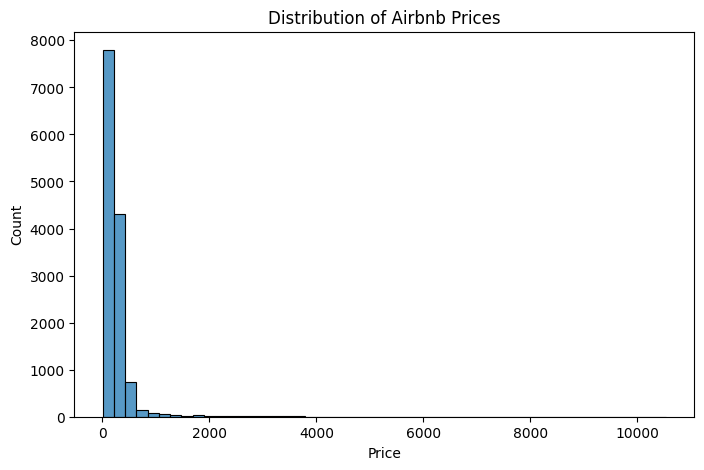

Original price skewness: 9.038044540465457


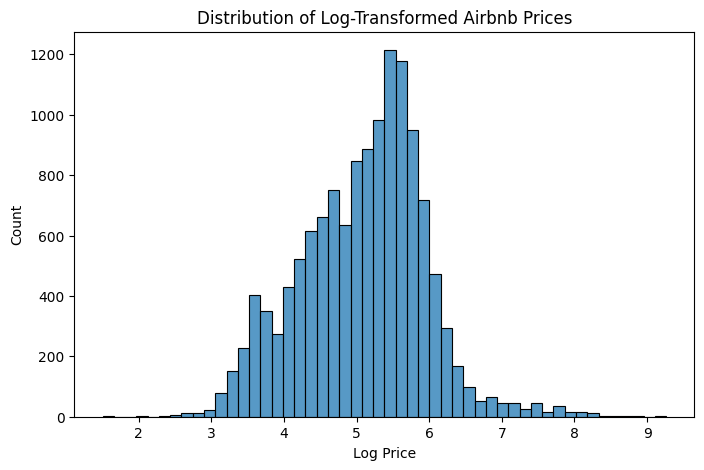

Log price skewness: 0.025893115223708803


In [4]:
# Check the distribution of price before transformation
plt.figure(figsize=(8, 5))
sns.histplot(df["price"].dropna(), bins=50)
plt.title("Distribution of Airbnb Prices")
plt.xlabel("Price")
plt.ylabel("Count")
plt.show()

# Check skewness
print("Original price skewness:", df["price"].skew())

# Apply a log transformation
df["log_price"] = np.log1p(df["price"])

# Plot the transformed price
plt.figure(figsize=(8, 5))
sns.histplot(df["log_price"].dropna(), bins=50)
plt.title("Distribution of Log-Transformed Airbnb Prices")
plt.xlabel("Log Price")
plt.ylabel("Count")
plt.show()

# Check transformed skewness
print("Log price skewness:", df["log_price"].skew())

## 2. Check for Skew in a Numeric Column

### Business framing:  

Airbnb listings can have a wide range of values for things like price, availability, or reviews. These kinds of distributions can be hard to visualize, summarize, or model.

### Do the following:
Choose one **numeric column** that appears skewed and do the following:
- Plot a histogram
- Apply a transformation (e.g., log or other method)
- Plot again to compare

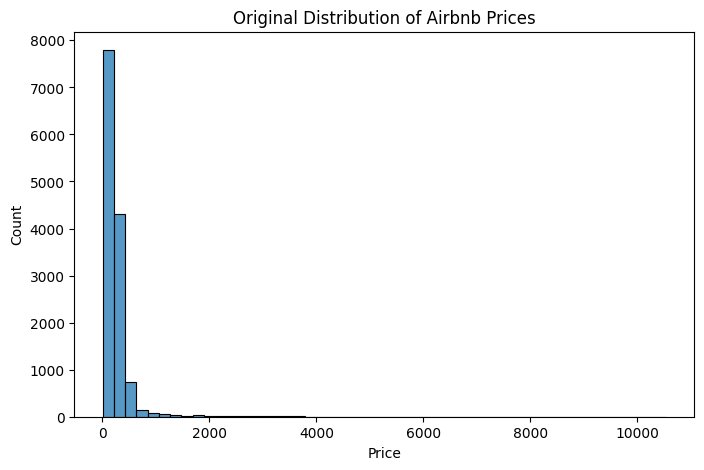

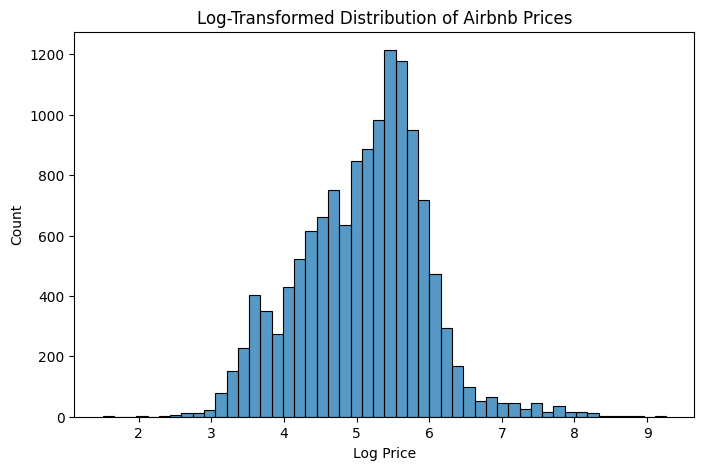

In [5]:
# Plot the original price distribution
plt.figure(figsize=(8, 5))
sns.histplot(df["price"].dropna(), bins=50)
plt.title("Original Distribution of Airbnb Prices")
plt.xlabel("Price")
plt.ylabel("Count")
plt.show()

# Apply a log transformation
df["log_price"] = np.log1p(df["price"])

# Plot the transformed price distribution
plt.figure(figsize=(8, 5))
sns.histplot(df["log_price"].dropna(), bins=50)
plt.title("Log-Transformed Distribution of Airbnb Prices")
plt.xlabel("Log Price")
plt.ylabel("Count")
plt.show()

### Reflection:
1. What column did you examine?
2. What transformation did you try, and why?
3. How did the transformed version help make the data more usable for analysis or stakeholder review?

### ✍️ Your Response: 🔧
1. I examined the price column because it had a wide range of values and appeared skewed.

2. I used a log transformation with np.log1p() to reduce the effect of very high-priced listings and make the distribution more balanced.

3. The transformed version made the data easier to visualize and compare because extreme prices had less influence on the graph. This makes it more useful for pricing analysis and for stakeholders trying to understand typical Airbnb prices.

## 3. Scale Two Numeric Columns

### Business framing:

If an analyst wanted to compare listing price to number of nights required, or create a model that weighs both, those values need to be on a similar scale.

### Do the following:
- Pick two numeric columns with different value ranges (e.g. one column may have a min of 0 and a max of 255; another column may have a min of 100 and a max of 400)
- Use Min-Max scaling on one column (the range should be “shrinked” down to just 0-1)
- Use Z-score Normalization (aka standardization) on the other column.
- Add 2 new columns to the dataset. These 2 new columns should be the ones you just created.

In [6]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Min-Max scale price
minmax = MinMaxScaler()
df["price_minmax"] = minmax.fit_transform(df[["price"]])

# Z-score scale minimum_nights
standard = StandardScaler()
df["minimum_nights_zscore"] = standard.fit_transform(df[["minimum_nights"]])

# Preview the new columns
print(df[["price", "price_minmax", "minimum_nights", "minimum_nights_zscore"]].head())


    price  price_minmax  minimum_nights  minimum_nights_zscore
0  409.00      0.038477             1.0              -0.611401
1  388.00      0.036485             2.0              -0.564583
2  397.13      0.037351             1.0              -0.611401
3   43.24      0.003771            31.0               0.793159
4  226.13      0.021125             1.0              -0.611401



### Reflection:
1. What two columns did you scale, and which methods did you use?
2. When might these scaled values be more useful than the originals?
3. Who at Airbnb might benefit from this transformation and why?

### ✍️ Your Response: 🔧
1. I scaled price using Min-Max scaling and minimum_nights using Z-score normalization.

2. The scaled values are more useful when comparing variables with very different ranges or when using them together in a model.

3. Airbnb analysts or data scientists could use these transformed values in pricing or recommendation models because neither variable would dominate just because of its original scale.

## 4. Group a Numeric Column into Categories

### Business framing:  

Let’s say an Airbnb marketing team wants to segment listings by review activity. They don’t want exact numbers — they just want to know if a listing has “low,” “medium,” or “high” review volume.

### Do the following:

- Choose a numeric column that could be grouped (e.g., reviews, availability).
- You’ll want to group the values of this column into 3 or 4 bins
- Create a new column. The values of this column will be the labels: “Low”, “Medium”, and “High.” These labels should correspond to your bins.

In [7]:
# Group number_of_reviews into Low, Medium, and High categories
df["review_volume"] = pd.qcut(
    df["number_of_reviews"],
    q=3,
    labels=["Low", "Medium", "High"]
)

# Preview the new column
print(df[["number_of_reviews", "review_volume"]].head())

# Check how many listings are in each category
print(df["review_volume"].value_counts())

   number_of_reviews review_volume
0                 59          High
1                 99          High
2                304          High
3                108          High
4                450          High
review_volume
Low       5575
High      5075
Medium    4643
Name: count, dtype: int64


### Reflection:
1. What column did you group, and how many categories did you use?
2. Why might someone prefer this grouped view over raw numbers?
3. Who would this help at Airbnb, and how?

### ✍️ Your Response: 🔧
1. I grouped the number_of_reviews column into three categories: Low, Medium, and High.

2. Someone might prefer the grouped view because it is easier to quickly compare listings than looking at exact review counts.

3. This could help Airbnb marketing teams or analysts segment listings based on review activity and identify which listings have low or high guest engagement.

## 5. Create Two New Business-Relevant Variables

### Business framing:  

Stakeholders often want to know things like: What’s the cost per night? Are listings geared toward long-term stays? These kinds of features aren’t always in the dataset — analysts create them.

### Do the following:

- Think of two new columns you can create using the data you already have.
  - One might be a ratio or interaction between columns (e.g., price ÷ nights).
  - The other might be a flag based on a condition (e.g., stays longer than 30 days).
- Add the new columns to your DataFrame.

In [8]:
# Create price per guest
df["price_per_guest"] = df["price"] / df["accommodates"]

# Create a long-term stay flag
df["long_term_stay"] = np.where(
    df["minimum_nights"] >= 30,
    "Yes",
    "No"
)

# Preview the new columns
print(df[[
    "price",
    "accommodates",
    "price_per_guest",
    "minimum_nights",
    "long_term_stay"
]].head())

    price  accommodates  price_per_guest  minimum_nights long_term_stay
0  409.00             8        51.125000             1.0             No
1  388.00             5        77.600000             2.0             No
2  397.13             9        44.125556             1.0             No
3   43.24             1        43.240000            31.0            Yes
4  226.13             4        56.532500             1.0             No


### Reflection:
1. What two new columns did you create and why?
2. Who would use them (e.g., host, manager, or platform)?
3. How could they help someone make a better decision?

### ✍️ Your Response: 🔧
1. I created price_per_guest by dividing price by the number of guests the listing accommodates, and long_term_stay to identify listings requiring stays of 30 nights or more.

2. Hosts, Airbnb managers, and platform analysts could use these variables.

3. price_per_guest can help compare the relative value of listings of different sizes, while long_term_stay can help identify listings that are more focused on extended stays rather than short-term travelers.



## 6. Encode a Categorical Column

### Business framing:  

Let’s say you’re helping the Airbnb data science team build a model to predict booking rates. Categorical columns like `room_type`, `neighbourhood`, or `cancellation_policy` can’t be used in models unless they’re converted to numbers.

### Do the following:
- Choose one categorical column from your dataset (e.g., room type or neighborhood group)
- Decide on an encoding method:
  - Use one-hot encoding for nominal (unordered) categories
  - Use ordinal encoding (a ranking) only if the categories have a clear order
- Apply the encoding using `pandas` or another tool
- Add the new encoded column(s) to your DataFrame

In [9]:
# One-hot encode room_type
room_type_encoded = pd.get_dummies(
    df["room_type"],
    prefix="room_type"
)

# Add the encoded columns back to the DataFrame
df = pd.concat([df, room_type_encoded], axis=1)

# Preview the new encoded columns
print(room_type_encoded.head())

# Check the updated DataFrame columns
print(df.filter(like="room_type").head())

   room_type_Entire home/apt  room_type_Hotel room  room_type_Private room  \
0                       True                 False                   False   
1                       True                 False                   False   
2                       True                 False                   False   
3                      False                 False                    True   
4                       True                 False                   False   

   room_type_Shared room  
0                  False  
1                  False  
2                  False  
3                  False  
4                  False  
         room_type  room_type_Entire home/apt  room_type_Hotel room  \
0  Entire home/apt                       True                 False   
1  Entire home/apt                       True                 False   
2  Entire home/apt                       True                 False   
3     Private room                      False                 False   
4  Entire home

### Reflection:
1. What column did you encode and why?
2. What encoding method did you use?
3. How could this transformation help a pricing model, dashboard, or business report?

### ✍️ Your Response: 🔧
1. I encoded the room_type column because it is categorical and would need to be converted into numbers before being used in a model.

2. I used one-hot encoding because the room types are nominal categories and do not have a natural ranking.

3. This transformation would help a pricing model or dashboard compare how different room types relate to price, demand, or booking behavior without incorrectly treating one room type as higher or lower than another.

## 7. Export Cleaned Data

Before wrapping up, export your cleaned Airbnb dataset to a CSV file. You'll need this file for **Assignment 11**, where you'll use the data in a regression model.

### Do the following:
Make sure your data has:
- Cleaned and consistent column values
- Proper data types for each column
- Any unnecessary columns removed

This file should be the version of your dataset that you’d feel confident sharing with a teammate or using for deeper analysis.



```
# Explanation:
# - "cleaned_airbnb_data_7.csv" is the name of the file that will be saved
# - index=False prevents pandas from writing row numbers into the CSV
# - The file will be saved to your working directory (in Colab, you'll need to download it manually. Once you see the data in your files tab, just click on the three dots, then click “download”)
# - YOU MAY NEED TO PRESS “RUN” MULTIPLE TIMES IN ORDER FOR IT TO SHOW UP
# - FOR SOME DEVICES, IT MAY TAKE A FEW MINUTES BEFORE YOUR FILE SHOWS UP

```

In [10]:
# Export the transformed Airbnb dataset
df.to_csv("/content/cleaned_airbnb_data_7.csv", index=False)

# Confirm the file was created
print("cleaned_airbnb_data_7.csv has been saved.")

cleaned_airbnb_data_7.csv has been saved.


## 8. Reflection

You’ve applied the same kinds of transformation techniques used in real Airbnb analytics projects — from pricing engines to host tools to tourism dashboards.

Now step back and reflect.

### Reflection:
1. What transformation step felt most important or interesting?
2. Which of your changes would be most useful to a host, analyst, or city planner?
3. If you were going to build a tool or dashboard, what would you do next with this data?
4. How does this relate to your customized learning outcome you created in canvas?



### ✍️ Your Response: 🔧

1. The most interesting transformation was creating new business-related variables, especially price_per_guest, because it turned existing columns into something that could be used more directly for comparisons and decisions.

2. I think price_per_guest and the long_term_stay flag would be especially useful to hosts and analysts. They make it easier to compare listings and identify which properties are aimed at different types of guests.

3. If I were building a dashboard, I would add filters for neighborhood, room type, price, review volume, and long-term stay status. I would also include charts that compare prices and listing performance across different areas.

4. This relates to my customized learning outcome because it gave me practice using data analysis to turn raw information into useful business insights. It also helped me improve my ability to use Python to prepare data and support business decisions.


## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [ ]:
!jupyter nbconvert --to html "assignment_07_data_transformation.ipynb"